# 01 데이터 열어 보기 — Speech Commands v0.02

제안서(11/22)의 데이터 칸에 쓸 내용을 만드는 노트북입니다.

- 출처·라이선스·크기·공식 분할 확인
- 단어별 녹음 수 (클래스 불균형)
- 예시 2개의 파형, 멜 스펙트로그램, 소리
- 녹음 길이 분포, 배경 잡음 파일과 잡음 섞기 예시
- 0번 기준(가장 많은 단어만 고르기)의 검증 점수

Colab에서는 런타임 → 모두 실행. 데이터(약 2.4GB)를 처음 한 번 내려받고 풀어서 몇 분 걸립니다. 그래프 글자는 Colab에 한글 글꼴이 없어 영어로 씁니다.

쓰는 라이브러리: 내려받기·분할·멜 스펙트로그램·잡음 섞기는 torchaudio, wav 파일 읽기는 soundfile입니다. torchaudio 2.9부터 `torchaudio.load`가 별도 패키지(torchcodec, FFmpeg 필요)를 요구해서 읽기만 soundfile로 합니다.

In [1]:
# 셀 1. 설정과 버전
import os, sys, time, random, collections
import numpy as np
import torch
import torchaudio
import soundfile as sf
import matplotlib
import matplotlib.pyplot as plt

SEED = 0
DATA_ROOT = "data"                                    # Colab: /content/data, 로컬: 팀프로젝트/data
SR = 16000                                            # 표본 추출률 (1초 = 16,000개)
N_FFT, HOP, N_MELS = 400, 160, 64                     # 25ms 창, 10ms 간격, 멜 밴드 64개

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchaudio", torchaudio.__version__,
      "| soundfile", sf.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # GPU가 있으면 GPU로 계산
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "GPU 없음 → CPU로 실행")

python 3.11.18 | torch 2.11.0+cu130 | torchaudio 2.11.0+cu130 | soundfile 0.14.0 | numpy 2.4.6 | matplotlib 3.11.2
device: cpu | GPU 없음 → CPU로 실행


In [2]:
# 셀 2. 내려받기와 공식 분할 (torchaudio.datasets.SPEECHCOMMANDS, 이미 있으면 내려받지 않음)
os.makedirs(DATA_ROOT, exist_ok=True)
t0 = time.time()
splits = {s: torchaudio.datasets.SPEECHCOMMANDS(DATA_ROOT, download=True, subset=sub)
          for s, sub in [("train", "training"), ("val", "validation"), ("test", "testing")]}
DATA_DIR = splits["train"]._path                      # .../SpeechCommands/speech_commands_v0.02
BASE_DIR = os.path.dirname(DATA_DIR)                  # get_metadata의 상대 경로 기준
print(f"준비 {time.time() - t0:.0f}초 | 위치 {DATA_DIR}")
print(sorted(f for f in os.listdir(DATA_DIR) if os.path.isfile(os.path.join(DATA_DIR, f)) and not f.startswith(".")))
print("라이선스:", open(os.path.join(DATA_DIR, "LICENSE"), encoding="utf-8").read().splitlines()[0])

# get_metadata는 소리를 읽지 않고 (경로, 표본 추출률, 단어, 화자, 번호)만 돌려줌
items = []                                            # (경로, 단어, 분할, 화자)
for s, ds in splits.items():
    for i in range(len(ds)):
        path, sr, word, spk, _ = ds.get_metadata(i)
        items.append((path, word, s, spk))
WORDS = sorted({w for _, w, _, _ in items})

준비 2초 | 위치 data\SpeechCommands\speech_commands_v0.02
['LICENSE', 'README.md', 'testing_list.txt', 'validation_list.txt']
라이선스: Attribution 4.0 International


단어 35개, 녹음 105,829개
분할: {'train': '84,843', 'val': '9,981', 'test': '11,005'}
화자: {'train': 2112, 'val': 256, 'test': 250} | 학습∩검증 0 | 학습∩시험 0
단어별 녹음 수: 최다 five 4,052, 최소 forward 1,557 (2.6배)


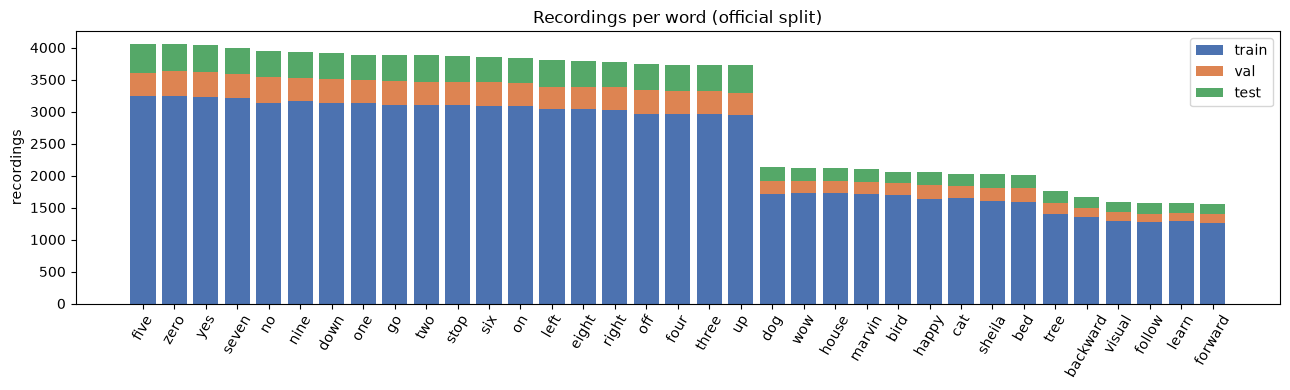

In [3]:
# 셀 3. 분할별 개수, 화자 겹침, 단어별 녹음 수
count = collections.Counter((w, s) for _, w, s, _ in items)
split_n = collections.Counter(s for _, _, s, _ in items)
speakers = {s: {spk for _, _, sp, spk in items if sp == s} for s in ["train", "val", "test"]}
print(f"단어 {len(WORDS)}개, 녹음 {len(items):,}개")
print("분할:", {s: f"{split_n[s]:,}" for s in ["train", "val", "test"]})
print("화자:", {s: len(v) for s, v in speakers.items()},
      "| 학습∩검증", len(speakers["train"] & speakers["val"]), "| 학습∩시험", len(speakers["train"] & speakers["test"]))

total = {w: sum(count[(w, s)] for s in ["train", "val", "test"]) for w in WORDS}
order = sorted(WORDS, key=lambda w: -total[w])
print(f"단어별 녹음 수: 최다 {order[0]} {total[order[0]]:,}, 최소 {order[-1]} {total[order[-1]]:,} ({total[order[0]] / total[order[-1]]:.1f}배)")

fig, ax = plt.subplots(figsize=(13, 4))
bottom = np.zeros(len(order))
for s, c in [("train", "#4C72B0"), ("val", "#DD8452"), ("test", "#55A868")]:
    v = np.array([count[(w, s)] for w in order])
    ax.bar(order, v, bottom=bottom, label=s, color=c); bottom += v
ax.set_ylabel("recordings"); ax.set_title("Recordings per word (official split)")
ax.legend(); plt.xticks(rotation=60); plt.tight_layout(); plt.show()

In [4]:
# 셀 4. 소리 읽기와 멜 스펙트로그램 (torchaudio.transforms)
def load_wav(path):
    """path는 get_metadata의 상대 경로 → (샘플 수,) float 텐서, -1~1"""
    x, sr = sf.read(os.path.join(BASE_DIR, path), dtype="float32")
    assert sr == SR
    return torch.from_numpy(x)

def pad_1s(x):
    """1초보다 짧으면 뒤를 0으로 채우고, 길면 자름"""
    return torch.nn.functional.pad(x, (0, max(0, SR - len(x))))[:SR]

mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS).to(device)
to_db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=80).to(device)

def log_mel(x):
    """(16000,) 파형 → (N_MELS, 101) 로그(dB) 멜 스펙트로그램. device에서 계산하고 그림용으로 CPU에 돌려줌"""
    return to_db(mel(x.to(device))).cpu()

print(mel)
print("1초 → 멜 스펙트로그램 모양", tuple(log_mel(pad_1s(torch.zeros(SR))).shape), "(멜 밴드, 시간 칸)")

MelSpectrogram(
  (spectrogram): Spectrogram()
  (mel_scale): MelScale()
)
1초 → 멜 스펙트로그램 모양 (64, 101) (멜 밴드, 시간 칸)


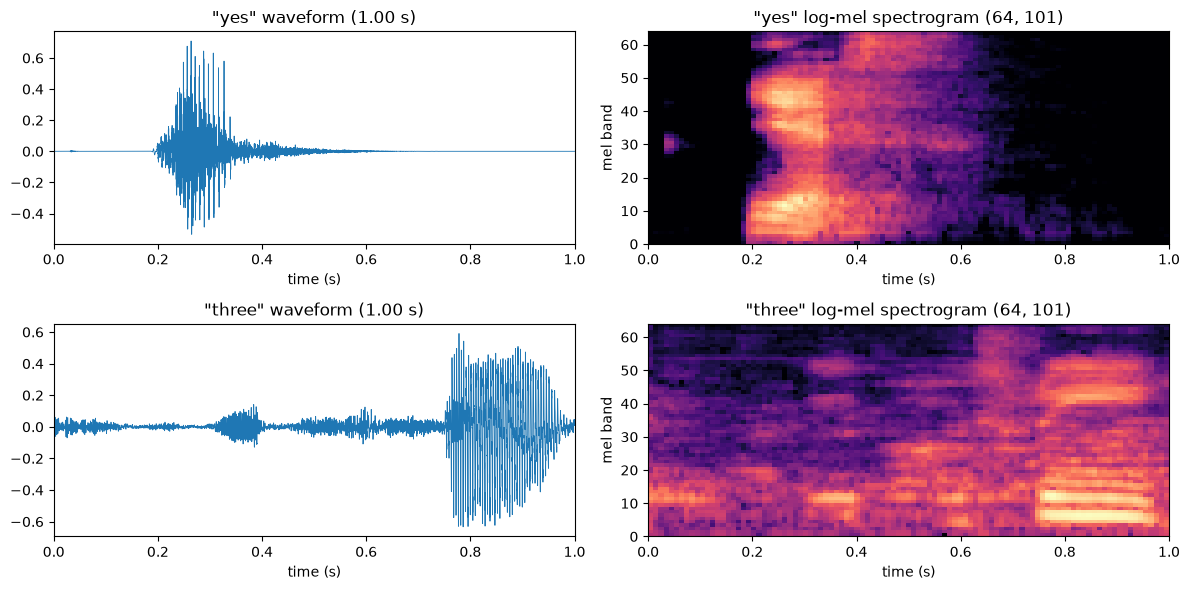

yes: speech_commands_v0.02\yes\7d6b4b10_nohash_1.wav (화자 7d6b4b10)


three: speech_commands_v0.02\three\9886d8bf_nohash_4.wav (화자 9886d8bf)


In [5]:
# 셀 5. 예시 2개 — 파형, 멜 스펙트로그램, 소리 (학습 묶음에서 시드 고정으로 고름)
from IPython.display import Audio, display
rng = random.Random(SEED)
examples = [rng.choice([it for it in items if it[1] == w and it[2] == "train"]) for w in ["yes", "three"]]

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for row, (path, w, s, spk) in enumerate(examples):
    x = load_wav(path)
    t = np.arange(len(x)) / SR
    axes[row, 0].plot(t, x.numpy(), lw=0.6); axes[row, 0].set_xlim(0, 1)
    axes[row, 0].set_title(f'"{w}" waveform ({len(x) / SR:.2f} s)'); axes[row, 0].set_xlabel("time (s)")
    m = log_mel(pad_1s(x))
    axes[row, 1].imshow(m.numpy(), origin="lower", aspect="auto", extent=[0, 1, 0, N_MELS], cmap="magma")
    axes[row, 1].set_title(f'"{w}" log-mel spectrogram {tuple(m.shape)}'); axes[row, 1].set_xlabel("time (s)"); axes[row, 1].set_ylabel("mel band")
plt.tight_layout(); plt.show()
for path, w, s, spk in examples:
    print(f"{w}: {path} (화자 {spk})")
    display(Audio(load_wav(path).numpy(), rate=SR))

105,829개를 7초에 확인


검증: 무작위 1,000개 중 실제 길이와 다른 파일 0개
1초 미만 10,435개 (9.9%), 최소 0.21초, 최대 1.00초 → 모두 1초로 맞춤 (짧으면 뒤를 0으로)


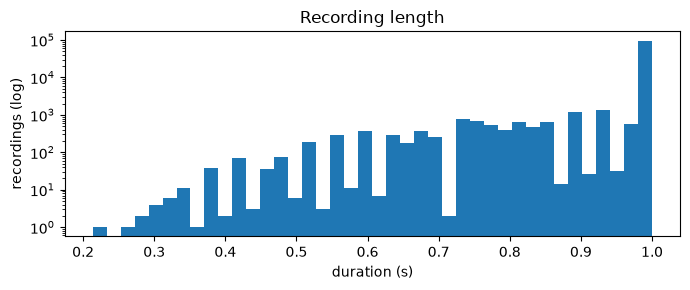

In [6]:
# 셀 6. 녹음 길이 분포
# 10만 개를 하나씩 열면 오래 걸려서 파일 크기로 계산: (크기 − 헤더 44바이트) ÷ (16,000 × 2바이트)
t0 = time.time()
durs = np.array([(os.path.getsize(os.path.join(BASE_DIR, p)) - 44) / (SR * 2) for p, *_ in items])
print(f"{len(durs):,}개를 {time.time() - t0:.0f}초에 확인")
check = random.Random(SEED).sample(range(len(items)), 1000)   # 1,000개는 soundfile로 실제 길이를 읽어 같은지 검증
mismatch = sum(abs(sf.info(os.path.join(BASE_DIR, items[i][0])).frames / SR - durs[i]) > 1e-6 for i in check)
print(f"검증: 무작위 1,000개 중 실제 길이와 다른 파일 {mismatch}개")
print(f"1초 미만 {np.sum(durs < 1.0):,}개 ({np.mean(durs < 1.0):.1%}), 최소 {durs.min():.2f}초, 최대 {durs.max():.2f}초 → 모두 1초로 맞춤 (짧으면 뒤를 0으로)")
plt.figure(figsize=(7, 3))
plt.hist(durs, bins=40); plt.yscale("log")
plt.xlabel("duration (s)"); plt.ylabel("recordings (log)"); plt.title("Recording length"); plt.tight_layout(); plt.show()

  doing_the_dishes.wav      95초
  dude_miaowing.wav         62초
  exercise_bike.wav         61초
  pink_noise.wav            60초
  running_tap.wav           61초
  white_noise.wav           60초


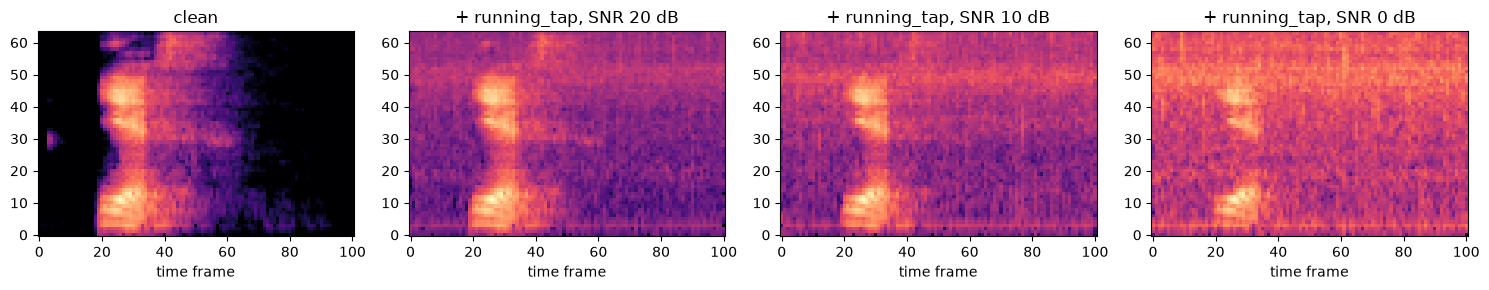

In [7]:
# 셀 7. 배경 잡음 파일과 잡음 섞기 예시 (torchaudio.functional.add_noise, 잡음 실험 준비)
noise_dir = os.path.join(DATA_DIR, "_background_noise_")
noises = {}
for f in sorted(os.listdir(noise_dir)):
    if f.endswith(".wav"):
        noises[f[:-4]] = load_wav(os.path.join(os.path.basename(DATA_DIR), "_background_noise_", f))
        print(f"  {f:<22s} {len(noises[f[:-4]]) / SR:5.0f}초")

def mix(x, noise, snr_db, rng):
    """잡음에서 1초를 무작위로 잘라 신호 대 잡음비(SNR)가 snr_db가 되게 섞음"""
    start = rng.randint(0, len(noise) - SR)
    n = noise[start:start + SR]
    snr = torch.tensor([float(snr_db)], device=device)
    return torchaudio.functional.add_noise(x.to(device).unsqueeze(0), n.to(device).unsqueeze(0), snr)[0].cpu()

x = pad_1s(load_wav(examples[0][0]))
rng = random.Random(SEED)
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, snr in zip(axes, [None, 20, 10, 0]):
    y = x if snr is None else mix(x, noises["running_tap"], snr, rng)
    ax.imshow(log_mel(y).numpy(), origin="lower", aspect="auto", cmap="magma")
    ax.set_title("clean" if snr is None else f"+ running_tap, SNR {snr} dB"); ax.set_xlabel("time frame")
plt.tight_layout(); plt.show()

In [8]:
# 셀 8. 0번 기준 — 학습 묶음에서 가장 많은 단어만 고르기
train_count = collections.Counter(w for _, w, s, _ in items if s == "train")
majority = train_count.most_common(1)[0][0]
val_words = [w for _, w, s, _ in items if s == "val"]
acc = np.mean([w == majority for w in val_words])
print(f"학습 묶음에서 가장 많은 단어: {majority} ({train_count[majority]:,}개)")
print(f"0번 기준 검증 정확도: {acc:.2%} (검증 {len(val_words):,}개 중 {sum(w == majority for w in val_words)}개)")
print(f"무작위로 고르기의 기댓값: 1/{len(WORDS)} = {1 / len(WORDS):.2%}")
# 매크로 F1: 한 단어만 고르면 그 단어의 F1만 0이 아니고 나머지 34개는 0
f1_major = 2 * acc * 1.0 / (acc + 1.0)                # 그 단어의 정밀도 = acc, 재현율 = 1
print(f"0번 기준 검증 매크로 F1: {f1_major / len(WORDS):.4f} (단어 {len(WORDS)}개 중 {majority}만 F1 {f1_major:.3f}, 나머지 0)")
print("시험 묶음은 마지막 평가에만 쓰므로 여기서는 계산하지 않음")

학습 묶음에서 가장 많은 단어: zero (3,250개)
0번 기준 검증 정확도: 3.85% (검증 9,981개 중 384개)
무작위로 고르기의 기댓값: 1/35 = 2.86%
0번 기준 검증 매크로 F1: 0.0021 (단어 35개 중 zero만 F1 0.074, 나머지 0)
시험 묶음은 마지막 평가에만 쓰므로 여기서는 계산하지 않음


In [9]:
# 셀 9. 제안서 데이터 칸 요약
print(f"""데이터: Google Speech Commands v0.02 (Warden, 2018), torchaudio.datasets.SPEECHCOMMANDS로 내려받음
라이선스: CC BY 4.0
크기: 단어 {len(WORDS)}개, 1초 내외 녹음 {len(items):,}개, 16kHz 모노 wav, 약 2.4GB
분할(공식 목록): 학습 {split_n['train']:,} / 검증 {split_n['val']:,} / 시험 {split_n['test']:,}, 화자 기준으로 나뉘어 학습·시험 화자가 겹치지 않음
불균형: 단어별 {total[order[-1]]:,}~{total[order[0]]:,}개 ({total[order[0]] / total[order[-1]]:.1f}배)
전처리: 1초로 맞춤(1초 미만 {np.mean(durs < 1.0):.1%}) → 로그 멜 스펙트로그램 ({N_MELS}, 101)
잡음: 배경 잡음 파일 {len(noises)}개로 잡음 섞은 시험 가능
0번 기준(검증): 정확도 {acc:.2%}, 매크로 F1 {f1_major / len(WORDS):.4f}""")

데이터: Google Speech Commands v0.02 (Warden, 2018), torchaudio.datasets.SPEECHCOMMANDS로 내려받음
라이선스: CC BY 4.0
크기: 단어 35개, 1초 내외 녹음 105,829개, 16kHz 모노 wav, 약 2.4GB
분할(공식 목록): 학습 84,843 / 검증 9,981 / 시험 11,005, 화자 기준으로 나뉘어 학습·시험 화자가 겹치지 않음
불균형: 단어별 1,557~4,052개 (2.6배)
전처리: 1초로 맞춤(1초 미만 9.9%) → 로그 멜 스펙트로그램 (64, 101)
잡음: 배경 잡음 파일 6개로 잡음 섞은 시험 가능
0번 기준(검증): 정확도 3.85%, 매크로 F1 0.0021
